# GCALS: Gradient Controlled Adaptive Label Smoothing

## Introduction
Label smoothing is a widely adopted regularization technique in deep learning. It modifies target distribution from one-hot encoding to a uniformly distributed probability mass. This restricts model from making overly confident predictions. It adds uncertainty to model's prediction.
<br>
<br>
Generally, we choose a label smoothing hyperparameter that remains constant throughout the training process. Alhough this will prevent model from making overly confident prediction, it can also add some restrictions to model in early training stages that will prevent it from learning sharp patterns in the beginning which can be beneficial because model will have some general idea of dataset in early stages. So, I formulated GCALS, an label smoothing parameter adapter that depends upon approximate confidence of the model with training data.
<br>
<br>
I decomposed gradient of CCE wrt logits into three distinct terms. Out of three, one is scaled gradient of CCE without LS, and other two are seen to be implicitly added due to label smoothing.


## Derivation

### Decomposing Loss

#### Loss Function Decomposition:




<br>

We start from defination of CCE loss with lable smoothing,

$$CCE_{LS}= - \sum_{i=1}^K P_i * log(\sigma_i)$$

Where,<br>
$K = Total \space number \space of \space class$<br>
$P = Smoothed \space targets$<br>
$\sigma = Softmax \space probabilities$<br><br>

Expanding the sum,
$$CCE_{LS}= - (1-\epsilon + \frac{\epsilon}{K}) * log(\sigma_t) - \sum_{j \neq t} P_j * log(\sigma_j)$$
<br><br>
Where $t$ represents index of correct class. This can be written as,

$$CCE_{LS}= L* (1-\epsilon + \frac{\epsilon}{K}) - \frac{\epsilon}{K} \sum_{i=1}^{K} (1-Y_i) *log(\sigma_i)$$
<br><br>
Where $L$ and $Y$ represent CCE Loss without label smoothing and one-hot encoding of targets respectively.
$$
CCE_{LS} = (1-\epsilon + \frac{\epsilon}{K})L + \text{Reg}(\sigma, Y)
$$
<br><br>
where, $\text{Reg}(\sigma, Y) = -\frac{\epsilon}{K-1}\sum_{i=1}^K (1-Y_i)\log(\sigma_i)$.
<br><br>

---
<br><br>


#### Finding Gradient: <br><br>



Differentiating $CCE_{LS}$ with respect to the model logits $z$ using the chain rule:<br><br>
$$
\frac{\partial CCE_{LS}}{\partial z} = (1-\epsilon + \frac{\epsilon}{K})\frac{\partial L}{\partial z} + \frac{\partial \text{Reg}}{\partial \sigma}\frac{\partial \sigma}{\partial z}
$$ <br><br>

Evaluating the derivative of the penalty term with respect to $\sigma$ elementwise gives:<br><br>
$$
\frac{\partial \text{Reg}}{\partial \sigma} = -\frac{\epsilon}{K-1}\frac{1-Y}{\sigma}
$$<br><br>

Combining this vector with the softmax Jacobian $\frac{\partial \sigma}{\partial z} = \text{diag}(\sigma) - \sigma\sigma^T$ and carrying out the matrix multiplication over transpose vectors yields the final decomposed gradient:<br><br>
$$
\frac{\partial CCE_{LS}}{\partial z} = (1-\epsilon + \frac{\epsilon}{K})\frac{\partial L}{\partial z} - \frac{\epsilon}{K-1}(1-Y) + \frac{K-1}{K}\epsilon\sigma
$$<br><br>

Here first term is scaled gradient of CCE without label smoothing and two other terms are seen to be implicitly added due to label smoothing. Let's write it as, <br><br>
$$
\frac{\partial CCE_{LS}}{\partial z} = G_1 + G_2
$$<br><br>

Where,<br><br>
$G_1 = (1-\epsilon + \frac{\epsilon}{K})\frac{\partial L}{\partial z}$<br><br>
$G_2 = \frac{K-1}{K}\epsilon\sigma - \frac{\epsilon}{K-1}(1-Y)$
<br><br>

---

<br><br>



### Formulating GCALS


During training process we can expect loss starting very large because the model hasn't learned any meaningful pattern in the provided data. Therefore, norm of $G_1$ can be expected to be relatively large. This symbolizes model is yet to learn the pattern. In contrast, in later stage of training, magnitude of $G_1$ becomes relatively smaller i.e. model has learned or almost learned the pattern of given data. While this is the optimization goal, this can also lead to overfitting. To prevent overfitting, label smoothing can be used. Adding label smoothing introduces new term $G_2$. Magnitude of $G_2$ depends upon softmax probabilities (i.e. confidence of model), as model make strongly confident predictions, higher magnitude of $G_2$ is added to the gradients, which during optimization penalizes the weights.  

<br><br>
Let's define a ratio $\gamma$ that measures the relative confidence of the model and is relative to L2 norm of both $G_1$ and $G_2$.
$$\gamma = \frac{\lVert G_2 \rVert_2}{\lVert G_1 \rVert_2 + \alpha}$$

<br><br> Where $\alpha$ is infinitesial value to prevent zero division error. Here we can see $\gamma$ measures how confident model is based on observed magnitude of gradient loss without label smoothing given the magnitude of gradient of regularizing term that is seen to be added into the gradient of loss implicitly due to label smoothing. Here magnitude of $G_2$ is multiplied to $\gamma$ to show $G_1$ is not what causing immediate behavior of the model.

<br><br>
$\gamma$ explodes to $\infty$ as $\lVert G_1 \rVert_2$ reaches 0. Which shows model is highly confident about it's prediction. Since label smoothing parameter has range $(0, 1)$ and we want label smoothing parameter to increase as model is becoming highly confident about its predictions, we use exponential saturation function on $\gamma$. <br><br>
$$\epsilon = \epsilon_{max} ⋅ (1 - e^{-\gamma})$$
<br><br> Where $\epsilon_{max}$ is the maximum value the label smoothing parameter can reach reasonably estimated by the user.
<br><br>
Additionally, we can also use exponential moving average on calculated $\epsilon$ to ensure \epsilon updates in smooth and stable way.<br><br>
$$\epsilon_{t} = (1 - \beta)\cdot \epsilon + \beta \cdot \epsilon_{t-1}$$
<br><br>Where $\beta$ is the decay factor.<br><br>

---
<br><br>

Note: <br>
In the code, I have set minimum value for $\epsilon$ because in early stage, it would be extremely small that the update in following epochs/ batches would be negligible.

## Experiment

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import ssl


In [ ]:

class GCALS(nn.Module):
    def __init__(self, eps_max=None, num_classes=10):
        super().__init__()
        self.min_epsilon = 0.0001
        self.epsilon = self.min_epsilon
        self.eps_max = eps_max
        self.num_classes = num_classes
        self.gamma = 0.0
        self.beta = 0.95

    def update_epsilon(self, logits, targets):
          with torch.no_grad():
                      softmaxes = F.softmax(logits, dim=-1)
                      y_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()

                      G_0 = (1.0 - self.epsilon) * (softmaxes - y_one_hot)

                      numerator = 1.0 - y_one_hot
                      G_1 = (self.epsilon) * ((self.num_classes - 1) / self.num_classes) * softmaxes - (self.epsilon / (self.num_classes - 1)) * numerator

                      f_grad_norm = torch.norm(G_0, p=2, dim=-1).mean().item()
                      f_reg_norm = torch.norm(G_1, p=2, dim=-1).mean().item()

                      self.gamma = f_reg_norm / (f_grad_norm + 1e-8)

                      target_epsilon = max(self.min_epsilon, self.eps_max * (1.0 - np.exp(-self.gamma)))

                      self.epsilon = (1.0 - self.beta) * target_epsilon + self.beta * self.epsilon



    def forward(self, logits, targets):
        loss = F.cross_entropy(logits, targets, label_smoothing=self.epsilon)
        self.update_epsilon(logits, targets)
        return loss


In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

ssl._create_default_https_context = ssl._create_unverified_context

torchvision.datasets.CIFAR10.url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
full_loader = torch.utils.data.DataLoader(train_dataset, batch_size=len(train_dataset), shuffle=False)

all_images, all_labels = next(iter(full_loader))
all_images, all_labels = all_images.to(device), all_labels.to(device)


100%|██████████| 170M/170M [00:18<00:00, 9.17MB/s]


In [ ]:
train_image, train_label = all_images[:30000], all_labels[:30000]
test_image, test_label = all_images[30000:], all_labels[30000:]

train = torch.utils.data.TensorDataset(train_image, train_label)
test = torch.utils.data.TensorDataset(test_image, test_label)


train_loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True, drop_last=True)
test_loader = torch.utils.data.DataLoader(test, batch_size=128, shuffle=False)

In [ ]:
num_epochs = 30
num_classes = 10


def train_track(mode="gcals", eps=None):
  torch.manual_seed(42)

  model = torchvision.models.resnet18(num_classes=num_classes)
  model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
  model.maxpool = nn.Identity()
  model = model.to(device)

  optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

  if mode == "gcals":
    criterion = GCALS(eps_max=eps, num_classes=num_classes)
  elif mode == "static":
    criterion = lambda lg, tg: F.cross_entropy(lg, tg, label_smoothing=eps)
  else:
    criterion = lambda lg, tg: F.cross_entropy(lg, tg, label_smoothing=0.0)

  train_loss_log = []
  test_loss_log = []
  test_acc_log = []
  eps_log = []

  print(f"\n--- Launching {mode.upper()} Track ---")
  for epoch in range(num_epochs):

    model.train()
    running_train_loss = 0.0
    num_train_batches = 0

    for x_batch, y_batch in train_loader:

      optimizer.zero_grad()

      logits = model(x_batch)
      train_loss = criterion(logits, y_batch)

      train_loss.backward()
      optimizer.step()

      running_train_loss += train_loss.item()
      num_train_batches += 1

    epoch_train_loss = running_train_loss / num_train_batches


    model.eval()
    running_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
      for x_test, y_test in test_loader:

        logits_test = model(x_test)

        loss_batch = F.cross_entropy(logits_test, y_test, reduction="sum")
        running_test_loss += loss_batch.item()

        _, predicted = logits_test.max(1)
        total += y_test.size(0)
        correct += predicted.eq(y_test).sum().item()

    epoch_test_loss = running_test_loss / total
    epoch_acc = 100.0 * correct / total

    current_eps = (
        criterion.epsilon
        if mode == "gcals"
        else (eps if mode == "static" else 0.0)
    )

    train_loss_log.append(epoch_train_loss)
    test_loss_log.append(epoch_test_loss)
    test_acc_log.append(epoch_acc)
    eps_log.append(current_eps)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {epoch_train_loss:.3f} | "
        f"Test Loss: {epoch_test_loss:.3f} | "
        f"Accuracy: {epoch_acc:.2f}% | "
        f"ε: {current_eps:.5f}"
    )


  return train_loss_log, test_loss_log, test_acc_log, eps_log


In [ ]:
eps = 0.1


In [ ]:
gcals_train, gcals_test, gcals_acc, gcals_epsilons = train_track(mode='gcals', eps=eps)


--- Launching GCALS Track ---
Epoch [1/30] | Train Loss: 1.319 | Test Loss: 1.317 | Accuracy: 54.85% | ε: 0.00010
Epoch [2/30] | Train Loss: 0.869 | Test Loss: 0.947 | Accuracy: 68.64% | ε: 0.00010
Epoch [3/30] | Train Loss: 0.642 | Test Loss: 0.966 | Accuracy: 67.70% | ε: 0.00010
Epoch [4/30] | Train Loss: 0.490 | Test Loss: 0.720 | Accuracy: 75.27% | ε: 0.00010
Epoch [5/30] | Train Loss: 0.358 | Test Loss: 0.786 | Accuracy: 74.97% | ε: 0.00010
Epoch [6/30] | Train Loss: 0.246 | Test Loss: 0.918 | Accuracy: 74.70% | ε: 0.00010
Epoch [7/30] | Train Loss: 0.175 | Test Loss: 0.939 | Accuracy: 75.03% | ε: 0.00010
Epoch [8/30] | Train Loss: 0.116 | Test Loss: 0.898 | Accuracy: 77.55% | ε: 0.00117
Epoch [9/30] | Train Loss: 0.205 | Test Loss: 0.642 | Accuracy: 79.95% | ε: 0.02477
Epoch [10/30] | Train Loss: 0.304 | Test Loss: 0.569 | Accuracy: 82.48% | ε: 0.04227
Epoch [11/30] | Train Loss: 0.326 | Test Loss: 0.552 | Accuracy: 83.09% | ε: 0.05189
Epoch [12/30] | Train Loss: 0.335 | Test Lo

In [ ]:
static_train, static_test, static_acc, static_epsilons = train_track(mode='static', eps=eps)


--- Launching STATIC Track ---
Epoch [1/30] | Train Loss: 1.540 | Test Loss: 1.199 | Accuracy: 57.55% | ε: 0.10000
Epoch [2/30] | Train Loss: 1.192 | Test Loss: 0.875 | Accuracy: 71.07% | ε: 0.10000
Epoch [3/30] | Train Loss: 1.012 | Test Loss: 0.988 | Accuracy: 66.58% | ε: 0.10000
Epoch [4/30] | Train Loss: 0.901 | Test Loss: 0.734 | Accuracy: 75.96% | ε: 0.10000
Epoch [5/30] | Train Loss: 0.791 | Test Loss: 0.708 | Accuracy: 76.76% | ε: 0.10000
Epoch [6/30] | Train Loss: 0.694 | Test Loss: 0.701 | Accuracy: 77.76% | ε: 0.10000
Epoch [7/30] | Train Loss: 0.622 | Test Loss: 0.814 | Accuracy: 75.11% | ε: 0.10000
Epoch [8/30] | Train Loss: 0.572 | Test Loss: 0.794 | Accuracy: 76.51% | ε: 0.10000
Epoch [9/30] | Train Loss: 0.539 | Test Loss: 0.715 | Accuracy: 78.22% | ε: 0.10000
Epoch [10/30] | Train Loss: 0.532 | Test Loss: 0.649 | Accuracy: 80.77% | ε: 0.10000
Epoch [11/30] | Train Loss: 0.529 | Test Loss: 0.863 | Accuracy: 74.53% | ε: 0.10000
Epoch [12/30] | Train Loss: 0.569 | Test L

In [ ]:
none_train, none_test, none_acc, none_epsilons = train_track(mode='none')


--- Launching NONE Track ---
Epoch [1/30] | Train Loss: 1.324 | Test Loss: 1.413 | Accuracy: 52.26% | ε: 0.00000
Epoch [2/30] | Train Loss: 0.873 | Test Loss: 1.012 | Accuracy: 66.62% | ε: 0.00000
Epoch [3/30] | Train Loss: 0.642 | Test Loss: 1.022 | Accuracy: 65.33% | ε: 0.00000
Epoch [4/30] | Train Loss: 0.497 | Test Loss: 0.696 | Accuracy: 76.27% | ε: 0.00000
Epoch [5/30] | Train Loss: 0.368 | Test Loss: 0.840 | Accuracy: 73.42% | ε: 0.00000
Epoch [6/30] | Train Loss: 0.260 | Test Loss: 0.741 | Accuracy: 77.42% | ε: 0.00000
Epoch [7/30] | Train Loss: 0.169 | Test Loss: 0.832 | Accuracy: 77.75% | ε: 0.00000
Epoch [8/30] | Train Loss: 0.125 | Test Loss: 0.907 | Accuracy: 77.28% | ε: 0.00000
Epoch [9/30] | Train Loss: 0.098 | Test Loss: 1.012 | Accuracy: 76.22% | ε: 0.00000
Epoch [10/30] | Train Loss: 0.073 | Test Loss: 1.039 | Accuracy: 77.61% | ε: 0.00000
Epoch [11/30] | Train Loss: 0.060 | Test Loss: 1.041 | Accuracy: 76.89% | ε: 0.00000
Epoch [12/30] | Train Loss: 0.069 | Test Los

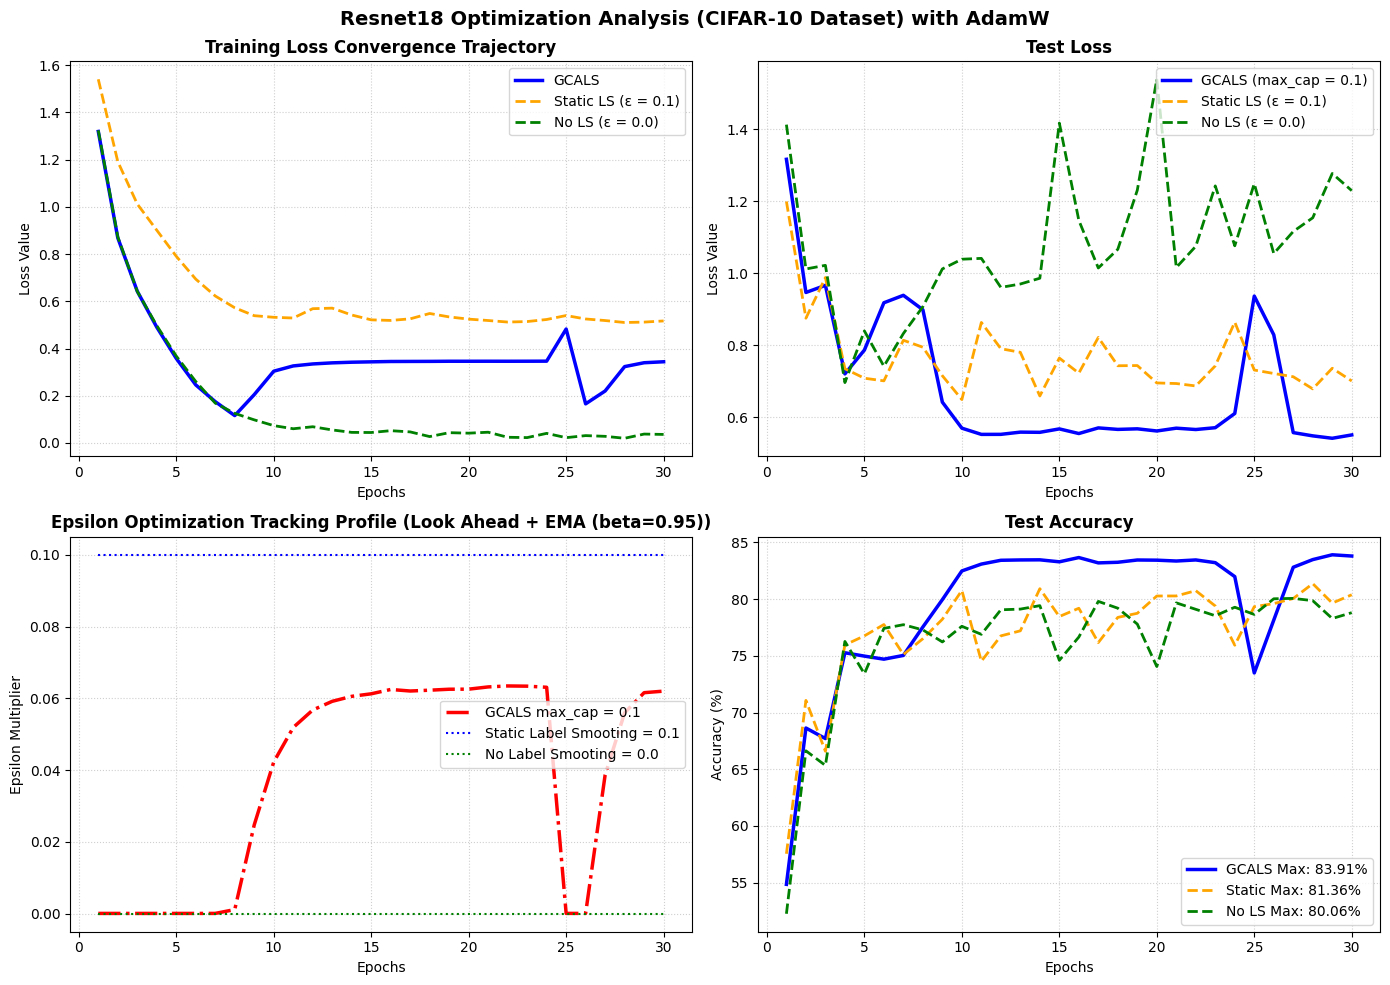

In [ ]:

epochs_range = range(1, num_epochs + 1)
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Train Loss
ax1.plot(epochs_range, gcals_train, color='blue', linewidth=2.5, label='GCALS')
ax1.plot(epochs_range, static_train, color='orange', linestyle='--', linewidth=2.0, label=f'Static LS (ε = {eps})')
ax1.plot(epochs_range, none_train, color='green', linestyle='--', linewidth=2.0, label=f'No LS (ε = 0.0)')
ax1.set_title('Training Loss Convergence Trajectory', fontweight='bold')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss Value')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Test Loss
ax2.plot(epochs_range, gcals_test, color='blue', linewidth=2.5, label=f'GCALS (max_cap = {eps})')
ax2.plot(epochs_range, static_test, color='orange', linestyle='--', linewidth=2.0, label=f'Static LS (ε = {eps})')
ax2.plot(epochs_range, none_test, color='green', linestyle='--', linewidth=2.0, label=f'No LS (ε = 0.0)')
ax2.set_title('Test Loss', fontweight='bold')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss Value')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

# Epsilon Trajectory
ax3.plot(epochs_range, gcals_epsilons, color='red', linestyle='-.', linewidth=2.5, label=f'GCALS max_cap = {eps} ')
ax3.plot(epochs_range, static_epsilons, color='blue', linestyle=':', linewidth=1.5, label=f'Static Label Smooting = {eps}')
ax3.plot(epochs_range, none_epsilons, color='green', linestyle=':', linewidth=1.5, label=f'No Label Smooting = 0.0')
ax3.set_title('Epsilon Optimization Tracking Profile (Look Ahead + EMA (beta=0.95))', fontweight='bold')
ax3.set_xlabel('Epochs')
ax3.set_ylabel('Epsilon Multiplier')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend()

# Test Accuracy Performance
ax4.plot(epochs_range, gcals_acc, color='blue', linewidth=2.5, label=f"GCALS Max: {max(gcals_acc):.2f}%")
ax4.plot(epochs_range, static_acc, color='orange', linestyle='--', linewidth=2.0, label=f"Static Max: {max(static_acc):.2f}%")
ax4.plot(epochs_range, none_acc, color='green', linestyle='--', linewidth=2.0, label=f"No LS Max: {max(none_acc):.2f}%")
ax4.set_title('Test Accuracy', fontweight='bold')
ax4.set_xlabel('Epochs')
ax4.set_ylabel('Accuracy (%)')
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.legend(loc='lower right')

plt.suptitle('Resnet18 Optimization Analysis (CIFAR-10 Dataset) with AdamW', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('gcals_cifar10_adamw_benchmark.png', dpi=300)
plt.show()


Here, the sudden $\epsilon$ collapse at around epoch 25 to 27, is caused due to sudden spike on train loss at epoch 25 we can see in panel 1. That sudden spike caused $\epsilon$ to drop for some time to prevent training loss to further increase. During that period, model's restrictions were removed, so model tried to memorize train data during that period which resulted in worse test performance. However, after training loss became stable again, $\epsilon$ returned to it's normal configurations and test benchmark again came back to stable state.
